<a href="https://colab.research.google.com/github/patrykost-a11y/proste-przetwarzanie-obrazow-python/blob/main/przetwarzanie_obrazow.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

https://commons.wikimedia.org/wiki/Special:FilePath/Lemon.jpg?width=800
Oryginał: (678, 960, 3)


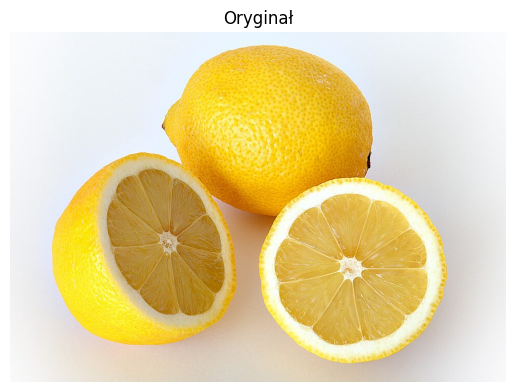

Po zmniejszeniu i grayscale: (339, 480)


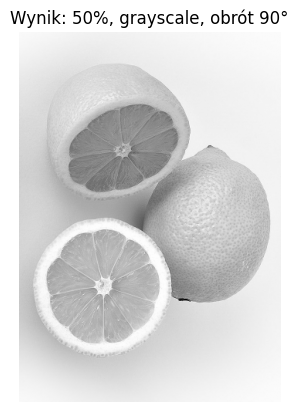

Kształt: (480, 339) | typ: uint8
[[250 250 250 ... 251 251 251]
 [250 250 249 ... 251 251 251]
 [249 249 249 ... 251 251 251]
 ...
 [248 248 248 ... 252 252 252]
 [249 249 249 ... 253 253 253]
 [250 250 250 ... 252 252 252]]


In [ ]:
import urllib.request
import numpy as np
import cv2
import matplotlib.pyplot as plt

# 1. Wczytanie obrazu zdalnego (urllib) – przykład z Wikimedia Commons
nazwa = "Lemon.jpg"
url = f"https://commons.wikimedia.org/wiki/Special:FilePath/{nazwa}?width=800"
print(url)
req = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0"})
with urllib.request.urlopen(req) as resp:
    data = np.asarray(bytearray(resp.read()), dtype=np.uint8)

img = cv2.imdecode(data, cv2.IMREAD_COLOR)      # BGR
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)      # RGB do wyświetlania
print("Oryginał:", img.shape)

# 2. Wyświetlenie oryginału
plt.imshow(img)
plt.title("Oryginał")
plt.axis("off")
plt.show()

# 3. Zmniejszenie o 50% + grayscale
small = cv2.resize(img, None, fx=0.5, fy=0.5, interpolation=cv2.INTER_AREA)
gray = cv2.cvtColor(small, cv2.COLOR_RGB2GRAY)
print("Po zmniejszeniu i grayscale:", gray.shape)

# 4. Obrót o 90 stopni
rotated = cv2.rotate(gray, cv2.ROTATE_90_CLOCKWISE)

# 5. Wyświetlenie obrazu wynikowego
plt.imshow(rotated, cmap="gray")
plt.title("Wynik: 50%, grayscale, obrót 90°")
plt.axis("off")
plt.show()

# 6. Macierz obrazu jako tablica liczb
print("Kształt:", rotated.shape, "| typ:", rotated.dtype)
print(rotated)
